# 02 - Time-based split and baseline

**Goal:** build the evaluation protocol (time-based split), train the first baseline model (logistic regression), and measure how much a random split would overestimate performance.

**Rules**
- The split is defined once in `src/data/split.py` and reused by every notebook.
- The test year (2017) and the late-check years (2018-2019) are not touched in this notebook. Models are developed on the validation year (2016) only.


## 0. Setup

Make the project folder importable and load the helpers from `src/data/split.py`.

In [2]:
import sys
sys.path.append("..")

import pandas as pd
from src.data.split import load_data, time_split, FEATURES, LABEL

## 1. Load the data and check the split

**Goal:** make sure the shared split code gives the same periods as the EDA notebook: sizes and label shares must match section 7 of `01_eda.ipynb`.

In [3]:
df = load_data()
train, validation, test, late = time_split(df)

for name, part in [("train", train), ("validation", validation), ("test", test), ("late check", late)]:
    print(name, len(part), round(part[LABEL].mean(), 3))

print(len(train) + len(validation) + len(test) + len(late) == len(df))

train 65957 0.293
validation 10606 0.291
test 10187 0.272
late check 19924 0.153
True


## 2. Baseline: logistic regression

**Goal:** train the simplest reasonable model and record its scores on the validation year (2016). Every later model has to beat this baseline.

**Preprocessing (decided in the EDA notebook):** `log1p` on the 11 skewed features, then standardization of all features. It is part of the pipeline, so it is learned on the training period only and then applied to validation without refitting.

**Class imbalance:** `class_weight="balanced"` gives more weight to the rare bug-inducing commits during training. The threshold stays at 0.5 for now; tuning it on validation comes in the next notebook.

**Metrics:** ROC-AUC (0.5 = chance), PR-AUC (chance = bug share, about 0.29), precision, recall, F1 and MCC (0 = chance). As a reference, the trivial model "everything is risky" is shown next to the baseline.

In [ ]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

from src.evaluation.metrics import evaluate

log_features = [f for f in FEATURES if f != "ent"]

preprocess = ColumnTransformer([
    ("log_and_scale", Pipeline(
        [("log", FunctionTransformer(np.log1p)),
        ("scale", StandardScaler())]), log_features),
    ("scale_only", StandardScaler(), ["ent"]),
])

baseline = Pipeline([
    ("preprocess", preprocess),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000)),
])

In [5]:
baseline.fit(train[FEATURES], train[LABEL])

val_proba = baseline.predict_proba(validation[FEATURES])[:, 1]
trivial = np.ones(len(validation))

results = pd.DataFrame({
    "logistic regression": evaluate(validation[LABEL], val_proba),
    "always predict bug-inducing": evaluate(validation[LABEL], trivial),
})
results.round(3)

,logistic regression,always predict bug-inducing
ROC-AUC,0.784,0.500
PR-AUC,0.601,0.291
precision,0.474,0.291
recall,0.772,1.000
F1,0.587,0.451
MCC,0.382,0.000
bug share,0.291,0.291


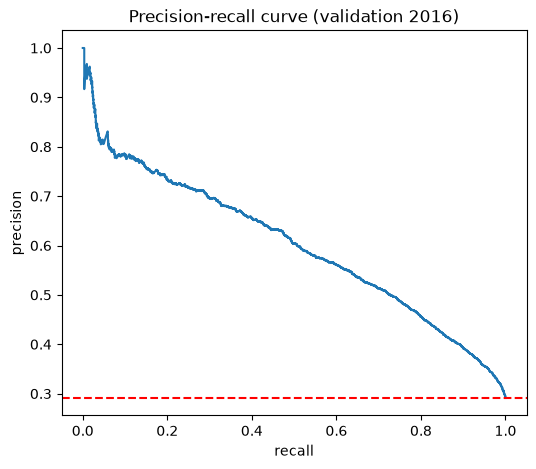

In [6]:
from sklearn.metrics import precision_recall_curve

precision, recall, _ = precision_recall_curve(validation[LABEL], val_proba)
curve = pd.DataFrame({"recall": recall, "precision": precision})

ax = curve.plot(x="recall", y="precision", figsize=(6, 5), title="Precision-recall curve (validation 2016)", legend=False)
ax.axhline(validation[LABEL].mean(), color="red", linestyle="--")
ax.set_ylabel("precision")
ax.figure.savefig("../reports/figures/02_baseline_pr_curve.png", dpi=150, bbox_inches="tight")

results.round(4).to_csv("../results/02_baseline_validation.csv")